In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Stile grafici
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [ ]:
df = pd.read_excel("../data/totx4t_hab.xlsx")

# ANALISI DELLE EMISSIONI DI GAS SERRA (ESCLUSI I 4 MEMO) PER I PAESI EUROPEI + NORVEGIA E ISLANDA
## Unità di misura: tonnellate di emissioni per capita

In [ ]:
df.head()
print(f"Dimensioni: {df.shape}")

,Austria,Belgium,Bulgaria,Cyprus,Czech Republic,Germany,Denmark,Estonia,Greece,Spain,...,Latvia,Malta,Netherlands,Norway,Poland,Portugal,Romania,Sweden,Slovenia,Slovakia
Year,,,,,,,,,,,,,,,,,,,,,
1990,10.4,14.6,11.4,9.6,19.0,15.8,14.1,25.7,10.2,7.4,...,9.8,7.4,14.9,12.1,12.5,5.9,11.1,8.3,9.4,13.9
1991,10.7,14.8,9.4,10.2,17.3,15.1,16.1,24.0,10.1,7.6,...,9.1,6.8,15.3,11.5,12.1,6.1,9.1,8.3,8.7,12.1
1992,9.8,14.7,8.8,10.7,16.8,14.4,14.9,17.8,10.1,7.8,...,7.4,6.8,15.2,11.1,11.8,6.5,8.5,8.2,8.7,11.0
1993,9.8,14.5,8.8,10.9,16.1,14.1,15.4,14.6,10.0,7.5,...,6.2,8.4,15.1,11.5,11.7,6.3,8.1,8.2,8.9,10.3
1994,9.7,14.9,8.4,11.0,15.3,13.9,16.1,15.2,10.2,7.8,...,5.6,7.7,15.1,11.8,11.5,6.4,8.0,8.4,9.1,9.7


In [138]:
df['Year'] = df["country"]
df = df.drop(columns=["country"])
df = df.set_index('Year')

### Analisi Missing value

In [184]:
print(f"\nMissing: {df.isnull().sum().sum()} valori ({df.isnull().any().any()})")


Missing: 0 valori (False)


### Emissioni medie per nazione (1990-2023)

In [185]:
media_per_nazione = df.mean().sort_values(ascending=False)
print(media_per_nazione)

Luxembourg        22.991176
Ireland           14.823529
Estonia           14.438235
Iceland           14.229412
Czech Republic    13.750000
Netherlands       12.735294
Finland           12.700000
Belgium           12.561765
Denmark           12.170588
Germany           11.938235
Norway            11.141176
Cyprus            10.847059
Poland            10.744118
Greece            10.202941
Austria            9.888235
Slovenia           9.173529
Slovakia           8.870588
Italy              8.679412
Bulgaria           8.288235
France             8.064706
Spain              7.914706
Hungary            7.123529
Romania            6.976471
Lithuania          6.955882
Sweden             6.761765
Portugal           6.747059
Malta              6.529412
Croatia            6.129412
Latvia             5.561765
dtype: float64


### Mariazione emissioni 1990 vs 2023

In [186]:
if 1990 in df.index and 2023 in df.index:
    variazione = ((df.loc[2023] - df.loc[1990]) / df.loc[1990] * 100).sort_values(ascending=False)
    print(variazione)
    print(f"\nPaesi con maggior riduzione: {variazione.head(3).to_dict()}")
    print(f"Paesi con maggior aumento: {variazione.tail(3).to_dict()}")

Croatia            0.000000
Cyprus            -7.291667
Portugal         -15.254237
Iceland          -17.241379
Poland           -24.000000
Spain            -24.324324
Slovenia         -25.531915
Austria          -27.884615
Italy            -29.347826
Norway           -29.752066
Greece           -32.352941
Ireland          -35.220126
Hungary          -37.362637
Bulgaria         -38.596491
France           -41.489362
Belgium          -43.150685
Malta            -44.594595
Latvia           -45.918367
Netherlands      -46.308725
Finland          -48.611111
Germany          -48.734177
Sweden           -49.397590
Czech Republic   -50.526316
Romania          -51.351351
Slovakia         -51.798561
Lithuania        -51.937984
Denmark          -53.191489
Luxembourg       -64.970060
Estonia          -69.260700
dtype: float64

Paesi con maggior riduzione: {'Croatia': 0.0, 'Cyprus': -7.29166666666666, 'Portugal': -15.254237288135597}
Paesi con maggior aumento: {'Denmark': -53.191489361702125, 'Lux

### Emissioni totali europee nel tempo

In [188]:
emissioni_totali = df.sum(axis=1)
print(emissioni_totali)

Year
1990    368.9
1991    358.8
1992    336.8
1993    330.5
1994    327.5
1995    320.6
1996    330.6
1997    324.5
1998    319.3
1999    314.0
2000    312.8
2001    318.8
2002    319.4
2003    327.4
2004    328.9
2005    323.9
2006    326.1
2007    326.4
2008    317.6
2009    293.2
2010    301.4
2011    292.1
2012    282.6
2013    275.9
2014    267.7
2015    264.8
2016    265.3
2017    267.1
2018    262.6
2019    249.8
2020    229.2
2021    237.7
2022    229.9
2023    211.8
dtype: float64


### Trend emissioni totali UE nel tempo 

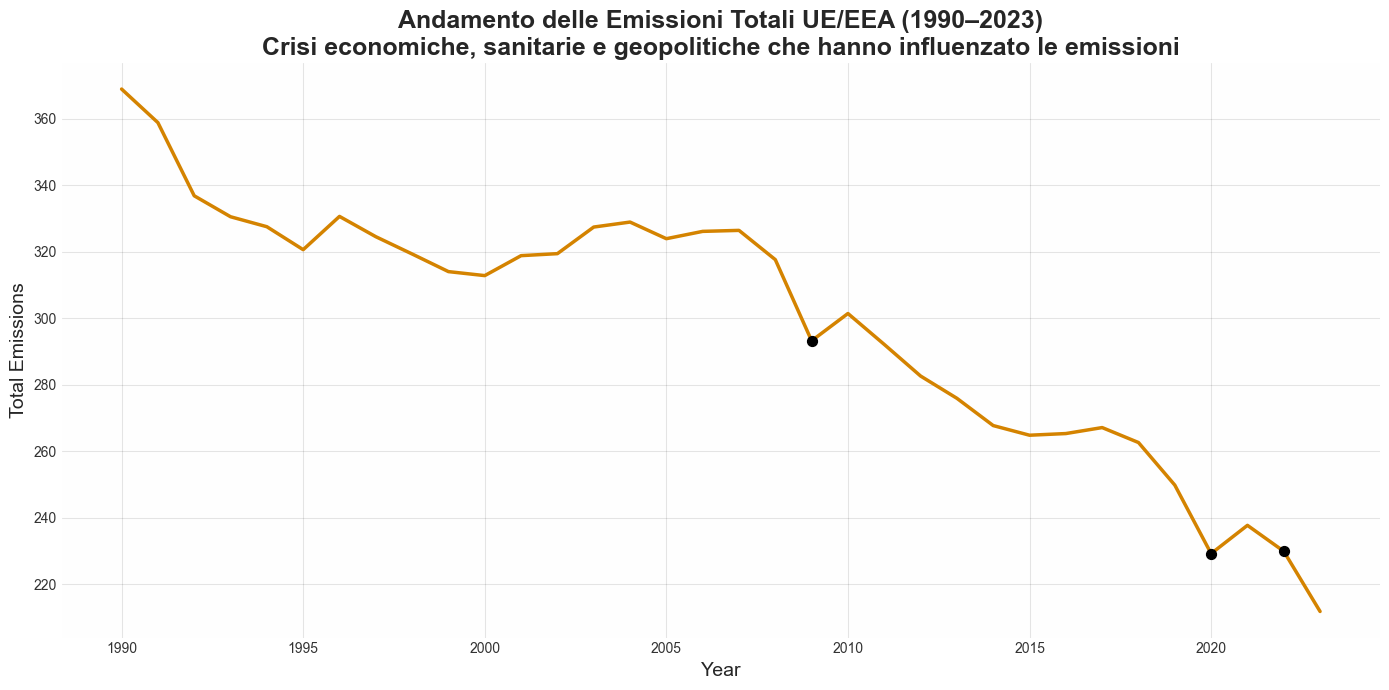

In [191]:
plt.figure(figsize=(14, 7))

# trend
plt.plot(df.index, emissioni_totali, color="#d48300", linewidth=2.5)

ax = plt.gca()
ax.set_facecolor("#f2f2f208")        # Colore interno del grafico
#plt.gcf().patch.set_facecolor("#f2f2f208")  # Colore esterno (intorno al grafico)

# punti di crisi da annotare
crisis_points = {
    2009: "Recessione globale",
    2020: "Pandemia\nCOVID-19",
    2022: "Conflitto Ucraina\n& Israele"
}

# tick degli eventi 
for year, label in crisis_points.items():
    if year in df.index:
        y = emissioni_totali.loc[year]
        plt.scatter(year, y, color="black", s=50, zorder=5)
        
# titolo
plt.title(
    "Andamento delle Emissioni Totali UE/EEA (1990–2023)\n"
    "Crisi economiche, sanitarie e geopolitiche che hanno influenzato le emissioni",
    fontsize=18,
    fontweight='bold'
)

# assi
plt.xlabel("Year", fontsize=14)
plt.ylabel("Total Emissions", fontsize=14)

plt.gca().spines['left'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.gca().spines['left'].set_color("#555555")
plt.gca().spines['bottom'].set_color("#555555")
plt.gca().tick_params(colors="#333333")

# griglia
plt.grid(alpha=0.1, color="black")

plt.tight_layout()
plt.show()

### 5 paesi con emissioni più alte 2023

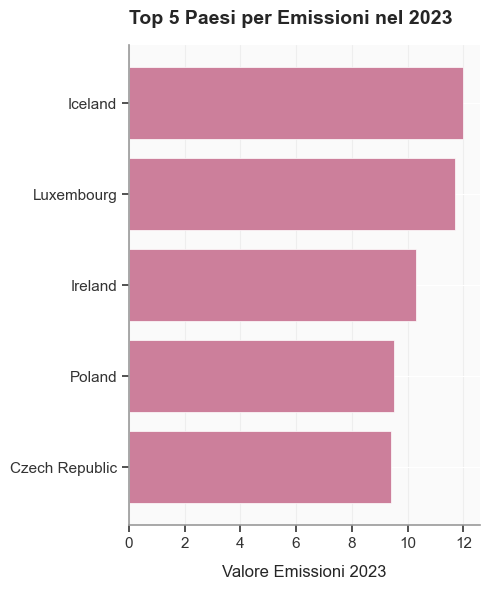

In [ ]:
fig, ax = plt.subplots(figsize=(5, 6))

# colore sfondo
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("white")

if 2023 in df.index:
    emissioni_2023 = df.loc[2023].sort_values(ascending=False)
    top5 = emissioni_2023.head(5)
    
    # barre orizzontali
    plt.barh(range(len(top5)), top5.values, color="#CC7F9B", 
             edgecolor='white', linewidth=0.5)
    
    # assi
    plt.yticks(range(len(top5)), top5.index, fontsize=12)
    plt.xlabel('Valore Emissioni 2023', fontsize=12, fontweight='medium', labelpad=10)

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color("#999999")
        ax.spines[spine].set_linewidth(1.2)
    
    ax.tick_params(colors="#333333", labelsize=11, length=5, width=1.2)

    # titolo
    plt.title('Top 5 Paesi per Emissioni nel 2023', 
              fontsize=14, fontweight='bold', pad=15, loc='left')
    
    # varori massimi in alto
    plt.gca().invert_yaxis()
    
    # griglia
    plt.grid(True, alpha=0.25, color="#cccccc", linestyle='-', 
             linewidth=0.8, axis='x', zorder=0)
    
    plt.tight_layout()
    #plt.savefig('top5_paesi_2023.png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

### 5 paesi con emissioni più alte 1990

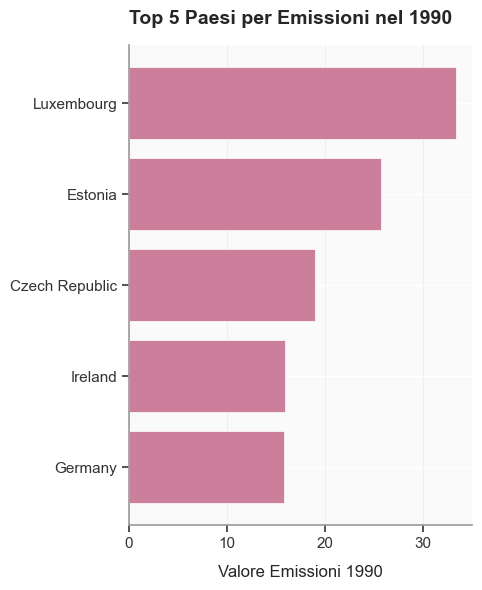

In [ ]:
fig, ax = plt.subplots(figsize=(5, 6))

# colore sfondo
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("white")

if 1990 in df.index:
    emissioni_1990 = df.loc[1990].sort_values(ascending=False)
    top5 = emissioni_1990.head(5)
    
    # barre orizzontali
    plt.barh(range(len(top5)), top5.values, color="#CC7F9B", 
             edgecolor='white', linewidth=0.5)
    
    # assi
    plt.yticks(range(len(top5)), top5.index, fontsize=12)
    plt.xlabel('Valore Emissioni 1990', fontsize=12, fontweight='medium', labelpad=10)

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color("#999999")
        ax.spines[spine].set_linewidth(1.2)

    ax.tick_params(colors="#333333", labelsize=11, length=5, width=1.2)
    
    # titolo
    plt.title('Top 5 Paesi per Emissioni nel 1990', 
              fontsize=14, fontweight='bold', pad=15, loc='left')
    
    # valori massimi in alto
    plt.gca().invert_yaxis()
    
    # griglia
    plt.grid(True, alpha=0.25, color="#cccccc", linestyle='-', 
             linewidth=0.8, axis='x', zorder=0)
    
    plt.tight_layout()
    #plt.savefig('top5_paesi_1990.png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

### Confronto emissioni 1990-2023

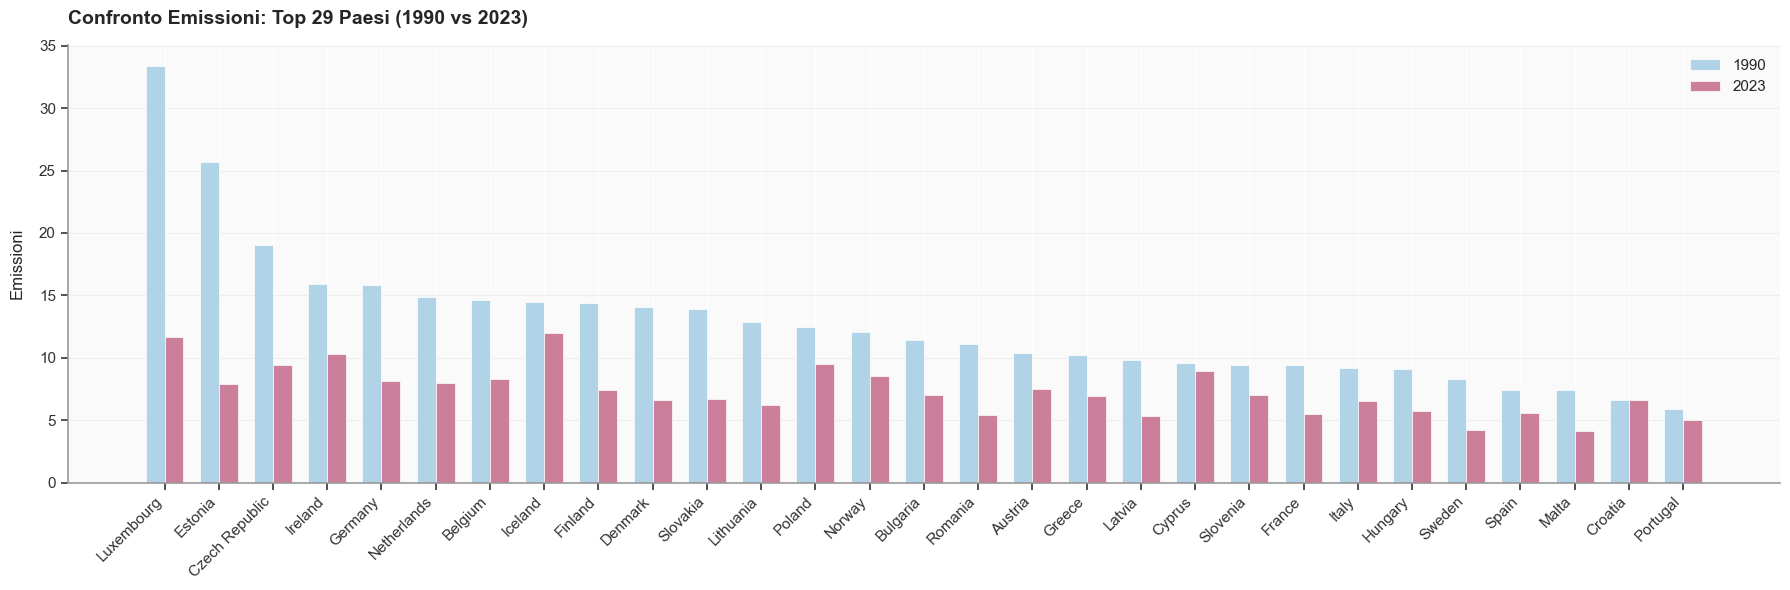

In [193]:
if 1990 in df.index and 2023 in df.index:
    emissioni_1990 = df.loc[1990].sort_values(ascending=False)
    top10_paesi = emissioni_1990.head(29).index
    
    dati_1990 = df.loc[1990, top10_paesi]
    dati_2023 = df.loc[2023, top10_paesi]
    
    fig, ax = plt.subplots(figsize=(18, 6))
    
    # colore sfondo
    ax.set_facecolor("#fafafa")
    fig.patch.set_facecolor("white")
    
    x = np.arange(len(top10_paesi))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, dati_1990.values, width, 
                    label='1990', color="#B1D3E8",
                    edgecolor='white', linewidth=0.5)
    bars2 = ax.bar(x + width/2, dati_2023.values, width, 
                    label='2023', color= "#CC7F9B",
                    edgecolor='white', linewidth=0.5)
    
    #assi
    ax.set_xticks(x)
    ax.set_xticklabels(top10_paesi, rotation=45, ha='right', fontsize=11)
    ax.set_ylabel('Emissioni', fontsize=12, fontweight='medium', labelpad=10)
    ax.set_title('Confronto Emissioni: Top 29 Paesi (1990 vs 2023)', 
                 fontsize=14, fontweight='bold', pad=15, loc='left')

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color("#999999")
        ax.spines[spine].set_linewidth(1.2)
    
    ax.tick_params(colors="#333333", labelsize=11, length=5, width=1.2)
    
    # legenda
    ax.legend(fontsize=11, frameon=True, fancybox=True, 
              framealpha=0, edgecolor='#cccccc')
    
    # griglia
    plt.grid(axis='y', alpha=0.25, color="#cccccc", linestyle='-', 
             linewidth=0.8, zorder=0)
    
    plt.tight_layout()
    #plt.savefig('confronto_top29_1990_vs_2023_vertical.png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
else:
    print("Anno 1990 o 2023 non presente nel dataset")

### Andamento principali paesi

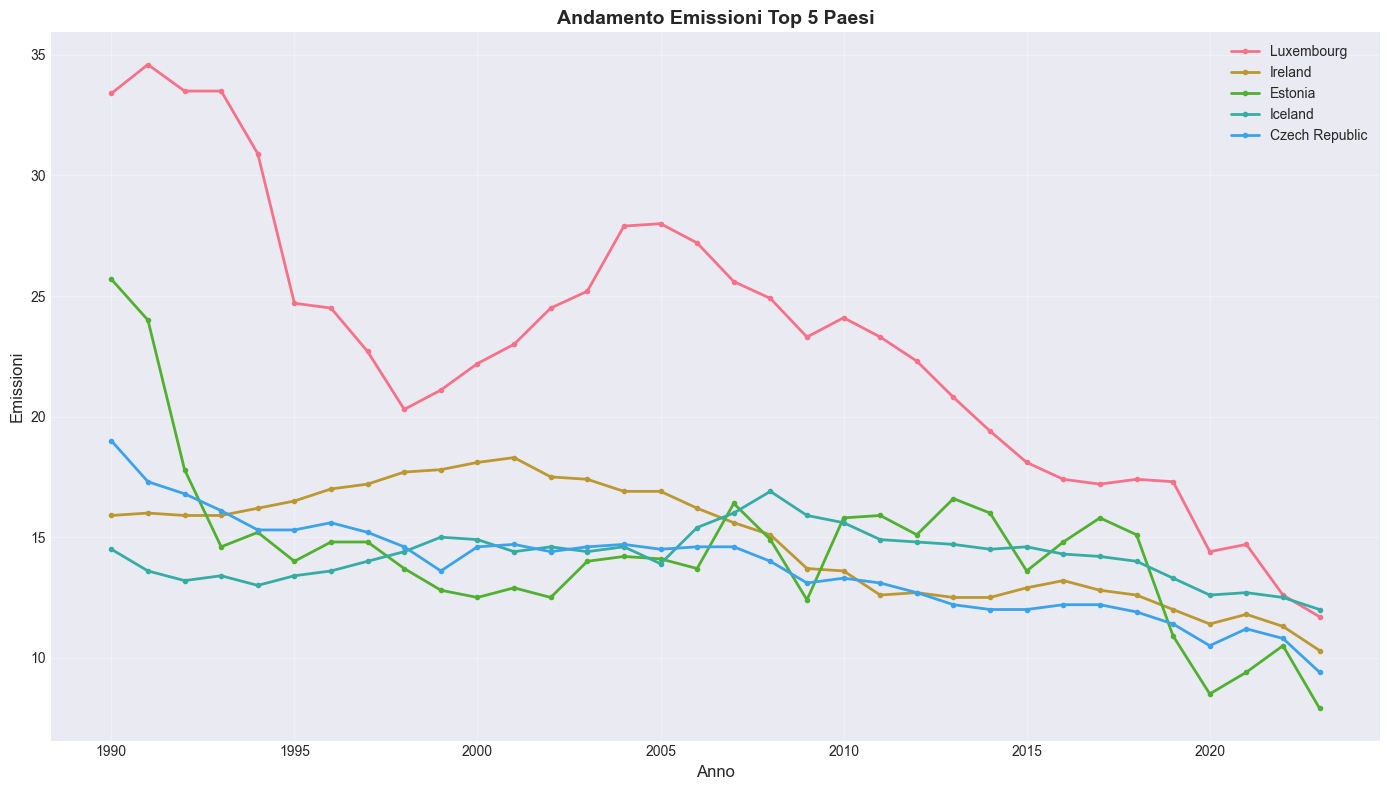

In [194]:
plt.figure(figsize=(14, 8))
top5_paesi = media_per_nazione.head(5).index
for paese in top5_paesi:
    plt.plot(df.index, df[paese], marker='o', markersize=3, label=paese, linewidth=2)
plt.title('Andamento Emissioni Top 5 Paesi', fontsize=14, fontweight='bold')
plt.xlabel('Anno', fontsize=12)
plt.ylabel('Emissioni', fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('andamento_top5.png', dpi=300, bbox_inches='tight')
plt.show()

### Tasso di crescita medio annuale (CAGR)

In [ ]:
if 1990 in df.index and 2023 in df.index:
    anni = 2023 - 1990
    cagr = ((df.loc[2023] / df.loc[1990]) ** (1/anni) - 1) * 100
    print("\n=== TASSO DI CRESCITA MEDIO ANNUALE (CAGR) ===")
    print(cagr.sort_values())


=== TASSO DI CRESCITA MEDIO ANNUALE (CAGR) ===
Estonia          -3.511496
Luxembourg       -3.128699
Denmark          -2.274063
Lithuania        -2.195771
Slovakia         -2.187185
Romania          -2.159808
Czech Republic   -2.109936
Sweden           -2.042997
Germany          -2.004325
Finland          -1.997205
Netherlands      -1.866957
Latvia           -1.845413
Malta            -1.773459
Belgium          -1.696851
France           -1.611008
Bulgaria         -1.467021
Hungary          -1.407600
Ireland          -1.307065
Greece           -1.177456
Norway           -1.064414
Italy            -1.047209
Austria          -0.985724
Slovenia         -0.889354
Spain            -0.841029
Poland           -0.828178
Iceland          -0.571819
Portugal         -0.500303
Cyprus           -0.229167
Croatia           0.000000
dtype: float64


### Contributo percentuale di ogni paese

In [ ]:
contributo_2023 = (df.loc[2023] / df.loc[2023].sum() * 100).sort_values(ascending=False)
print("\n=== CONTRIBUTO PERCENTUALE AL TOTALE (2023) ===")
print(contributo_2023)


=== CONTRIBUTO PERCENTUALE AL TOTALE (2023) ===
Iceland           5.665722
Luxembourg        5.524079
Ireland           4.863078
Poland            4.485364
Czech Republic    4.438149
Cyprus            4.202077
Norway            4.013220
Belgium           3.918791
Germany           3.824363
Netherlands       3.777148
Estonia           3.729934
Austria           3.541076
Finland           3.493862
Slovenia          3.305005
Bulgaria          3.305005
Greece            3.257790
Slovakia          3.163362
Denmark           3.116147
Croatia           3.116147
Italy             3.068933
Lithuania         2.927290
Hungary           2.691218
Spain             2.644004
France            2.596789
Romania           2.549575
Latvia            2.502361
Portugal          2.360718
Sweden            1.983003
Malta             1.935788
Name: 2023, dtype: float64


### Grafico a torta dei contributi 2023

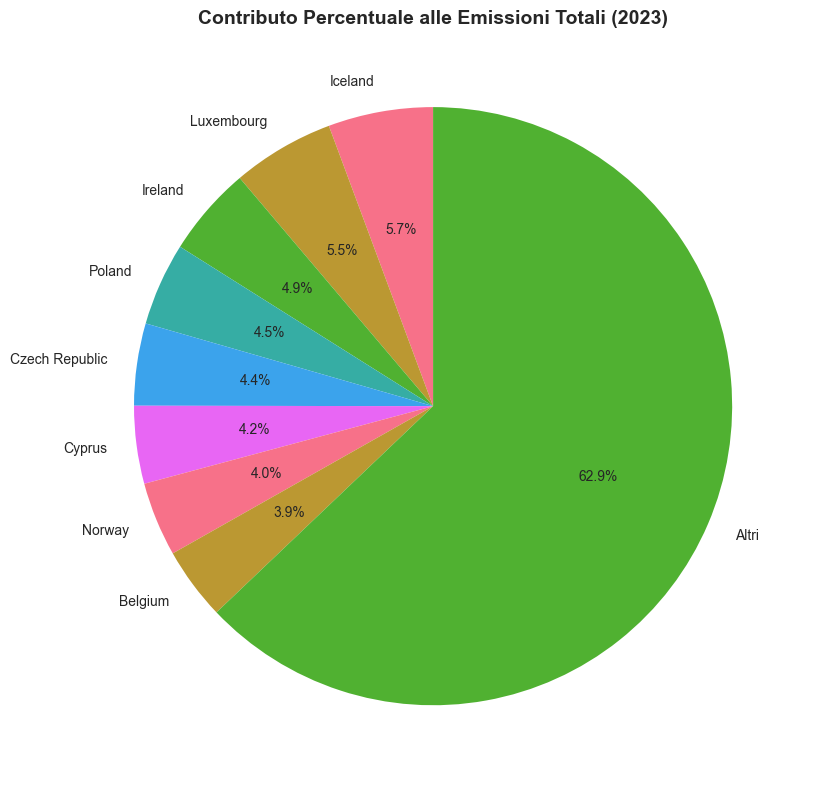

In [ ]:
plt.figure(figsize=(12, 8))
# Raggruppa paesi piccoli in "Altri"
top_contributors = contributo_2023.head(8)
altri = contributo_2023.iloc[8:].sum()
contributi_plot = pd.concat([top_contributors, pd.Series({'Altri': altri})])
plt.pie(contributi_plot.values, labels=contributi_plot.index, autopct='%1.1f%%', startangle=90)
plt.title('Contributo Percentuale alle Emissioni Totali (2023)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('contributi_2023.png', dpi=300, bbox_inches='tight')
plt.show()

### Clustering

In [33]:
# TRASPOSIZIONE: Paesi come righe, anni come colonne
df_t = df.T
df_t.head()

Year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Austria,10.4,10.7,9.8,9.8,9.7,10.1,10.5,10.5,10.4,10.2,...,9.0,9.2,9.2,9.4,9.0,9.1,8.4,8.7,8.1,7.5
Belgium,14.6,14.8,14.7,14.5,14.9,15.1,15.4,14.6,15.1,14.4,...,10.2,10.5,10.3,10.3,10.3,10.1,9.3,9.5,8.8,8.3
Bulgaria,11.4,9.4,8.8,8.8,8.4,8.6,8.7,8.4,7.9,7.1,...,8.1,8.7,8.4,8.8,8.2,8.2,7.3,8.3,9.0,7.0
Cyprus,9.6,10.2,10.7,10.9,11.0,10.7,11.1,11.1,11.4,11.7,...,9.7,9.8,10.3,10.4,10.1,9.6,9.0,9.1,9.0,8.9
Czech Republic,19.0,17.3,16.8,16.1,15.3,15.3,15.6,15.2,14.6,13.6,...,12.0,12.0,12.2,12.2,11.9,11.4,10.5,11.2,10.8,9.4


In [34]:
# Standardizzazione
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_t)

In [36]:
# Determinare il numero ottimale di cluster con il metodo del gomito
inertia = []
K = range(2, 10)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)

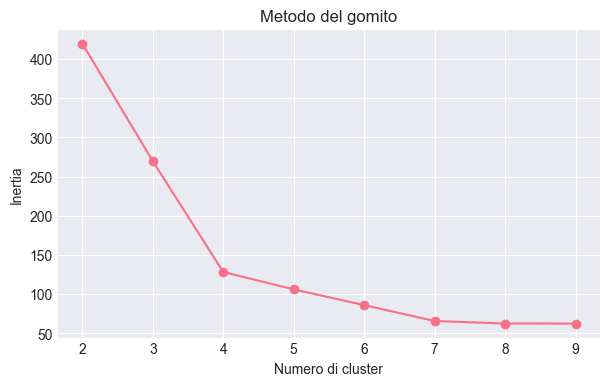

In [37]:
plt.figure(figsize=(7,4))
plt.plot(K, inertia, marker='o')
plt.title('Metodo del gomito')
plt.xlabel('Numero di cluster')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [ ]:
# K ottimale = 4
k_opt = 4
kmeans = KMeans(n_clusters=k_opt, random_state=42)
labels = kmeans.fit_predict(df_scaled)

In [39]:
# Aggiungiamo i cluster al dataframe trasposto
df_t['cluster'] = labels

In [43]:
print(df_t)

Year            1990  1991  1992  1993  1994  1995  1996  1997  1998  1999  \
Austria         10.4  10.7   9.8   9.8   9.7  10.1  10.5  10.5  10.4  10.2   
Belgium         14.6  14.8  14.7  14.5  14.9  15.1  15.4  14.6  15.1  14.4   
Bulgaria        11.4   9.4   8.8   8.8   8.4   8.6   8.7   8.4   7.9   7.1   
Cyprus           9.6  10.2  10.7  10.9  11.0  10.7  11.1  11.1  11.4  11.7   
Czech Republic  19.0  17.3  16.8  16.1  15.3  15.3  15.6  15.2  14.6  13.6   
Germany         15.8  15.1  14.4  14.1  13.9  13.7  13.9  13.5  13.2  12.7   
Denmark         14.1  16.1  14.9  15.4  16.1  15.4  17.8  15.9  15.1  14.6   
Estonia         25.7  24.0  17.8  14.6  15.2  14.0  14.8  14.8  13.7  12.8   
Greece          10.2  10.1  10.1  10.0  10.2  10.4  10.6  11.0  11.5  11.4   
Spain            7.4   7.6   7.8   7.5   7.8   8.2   8.0   8.3   8.5   9.1   
Finland         14.4  13.9  13.5  13.9  14.9  14.1  15.3  14.9  14.2  14.0   
France           9.4   9.8   9.6   9.1   9.0   9.0   9.3   9.1  

In [56]:
df_t.to_csv("cluster_europei_emissioni.csv")